# Demographics and Offer Performance Visualization

This notebook provides a visual companion to the Starbucks Rewards EDA. It combines customer demographics from `profile.json`, offer design from `portfolio.json`, and offer lifecycle events from `transcript.json`.

The charts are descriptive: they show who is represented in the data and how offers move through the received → viewed → completed funnel. They do not claim causal uplift.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"bogo": "#2a9d8f", "discount": "#e9c46a", "informational": "#457b9d"}
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
print(f"Project root: {ROOT}")

Project root: D:\SanJose\sem2\CMPE252


In [2]:
def load_json_lines(filename):
    with (RAW / filename).open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

profile = pd.DataFrame(load_json_lines("profile.json"))
portfolio = pd.DataFrame(load_json_lines("portfolio.json"))
transcript = pd.DataFrame(load_json_lines("transcript.json"))

# Age 118 is the known missing-value sentinel in this dataset.
profile["age_clean"] = profile["age"].replace(118, np.nan)
profile["income_k"] = profile["income"] / 1000
profile["member_year"] = pd.to_datetime(profile["became_member_on"].astype(str), format="%Y%m%d").dt.year
profile["age_band"] = pd.cut(profile["age_clean"], bins=[0, 24, 34, 44, 54, 64, 200], labels=["18–24", "25–34", "35–44", "45–54", "55–64", "65+"], include_lowest=True)

# Normalize nested transcript values into columns.
value = pd.json_normalize(transcript["value"].fillna({}))
events = pd.concat([transcript[["person", "event", "time"]].reset_index(drop=True), value.reset_index(drop=True)], axis=1)
events["offer_id"] = events["offer id"].fillna(events.get("offer_id"))
events = events.merge(portfolio[["id", "offer_type"]], left_on="offer_id", right_on="id", how="left")

print(f"Profiles: {len(profile):,}; offers: {len(portfolio)}; events: {len(events):,}")

Profiles: 17,000; offers: 10; events: 306,534


## 1. Customer demographics

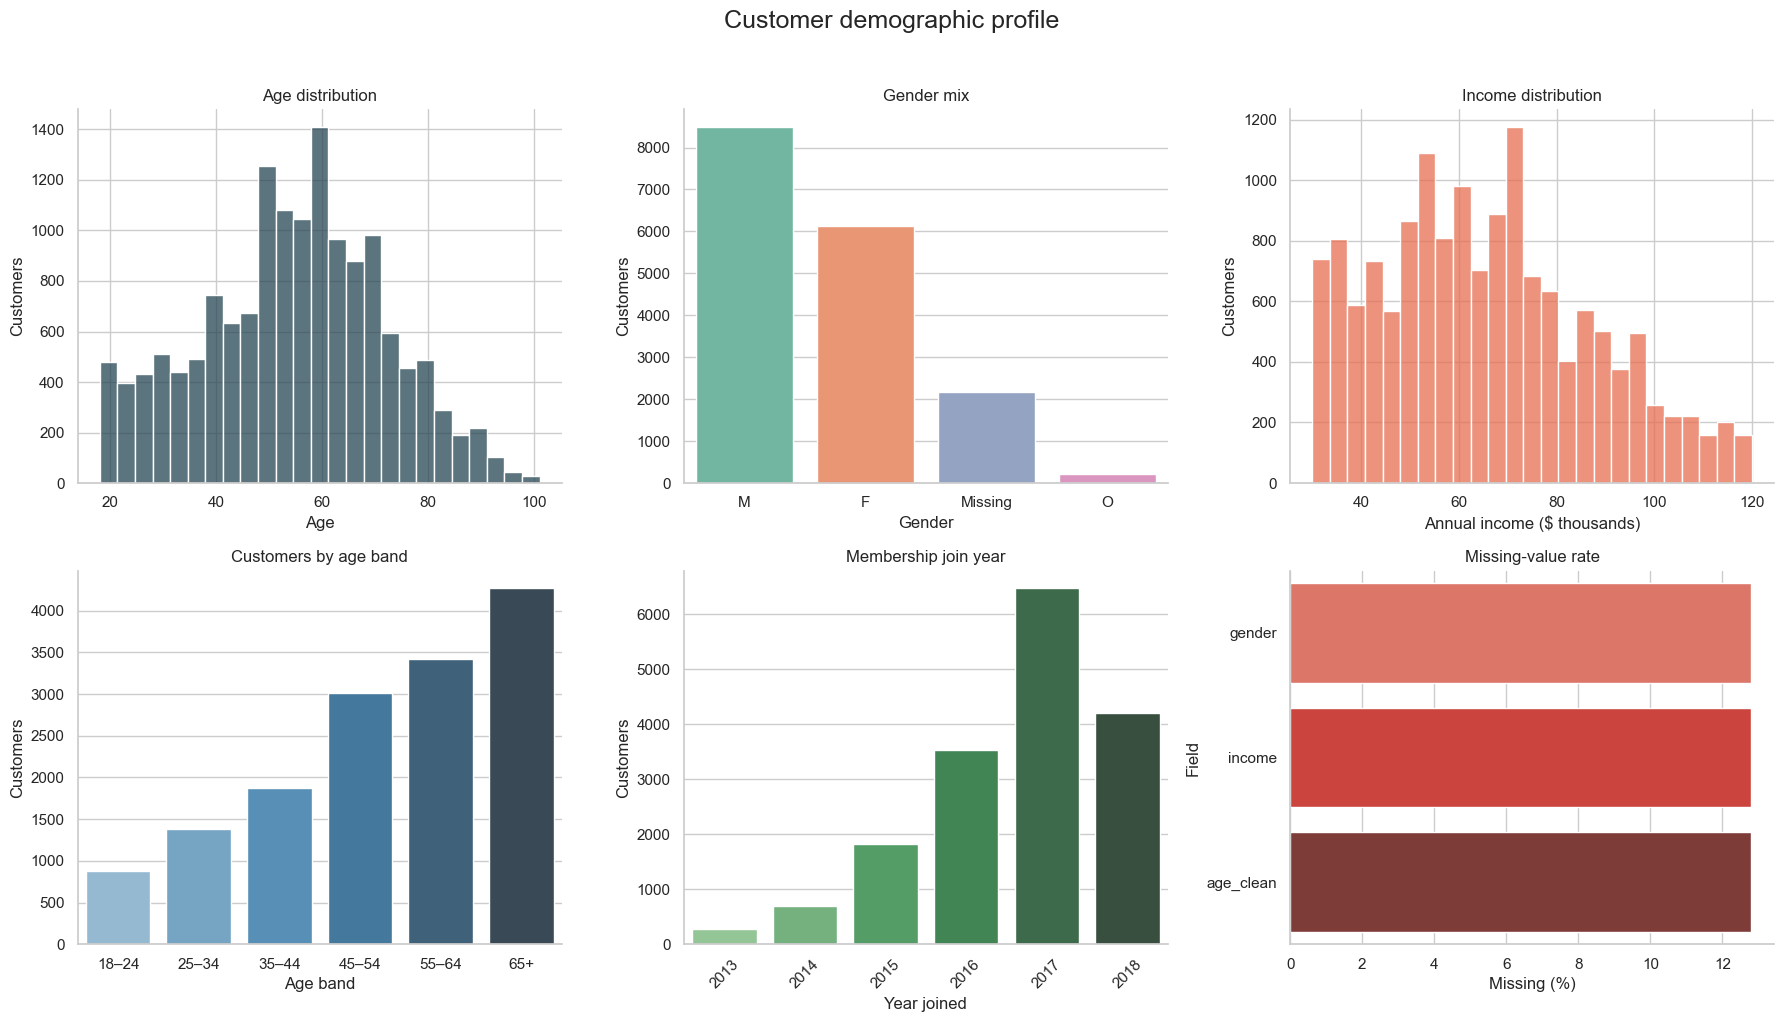

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Customer demographic profile", fontsize=18, y=1.02)

sns.histplot(profile["age_clean"].dropna(), bins=25, color="#264653", ax=axes[0, 0])
axes[0, 0].set(title="Age distribution", xlabel="Age", ylabel="Customers")

gender = profile["gender"].fillna("Missing").value_counts()
sns.barplot(x=gender.index, y=gender.values, hue=gender.index, palette="Set2", legend=False, ax=axes[0, 1])
axes[0, 1].set(title="Gender mix", xlabel="Gender", ylabel="Customers")

sns.histplot(profile["income_k"].dropna(), bins=25, color="#e76f51", ax=axes[0, 2])
axes[0, 2].set(title="Income distribution", xlabel="Annual income ($ thousands)", ylabel="Customers")

age_band = profile["age_band"].value_counts().sort_index()
sns.barplot(x=age_band.index, y=age_band.values, hue=age_band.index, palette="Blues_d", legend=False, ax=axes[1, 0])
axes[1, 0].set(title="Customers by age band", xlabel="Age band", ylabel="Customers")

member_year = profile["member_year"].value_counts().sort_index()
sns.barplot(x=member_year.index.astype(str), y=member_year.values, hue=member_year.index.astype(str), palette="Greens_d", legend=False, ax=axes[1, 1])
axes[1, 1].set(title="Membership join year", xlabel="Year joined", ylabel="Customers")
axes[1, 1].tick_params(axis="x", rotation=45)

missing = profile[["gender", "income", "age_clean"]].isna().mean().mul(100).sort_values(ascending=False)
sns.barplot(x=missing.values, y=missing.index, hue=missing.index, palette="Reds_d", legend=False, ax=axes[1, 2])
axes[1, 2].set(title="Missing-value rate", xlabel="Missing (%)", ylabel="Field")
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 2. Offer portfolio design

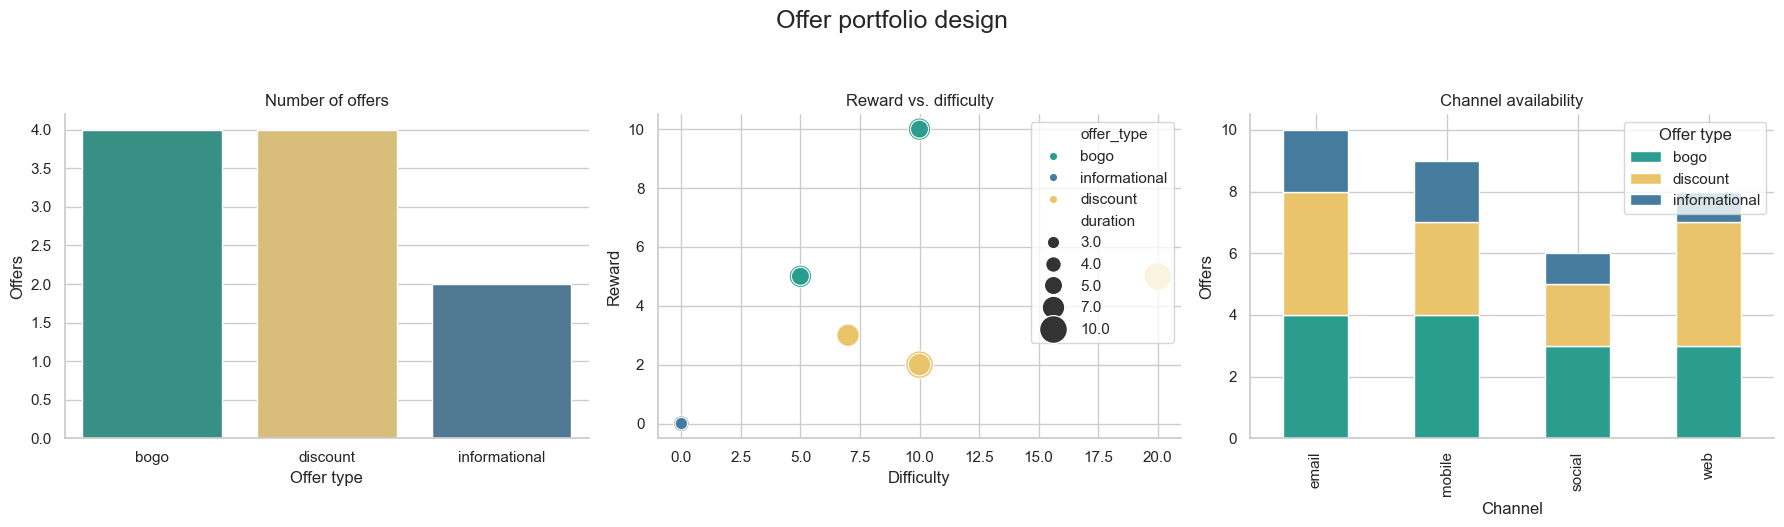

,offer_type,offers,avg_reward,avg_difficulty,avg_duration
0,bogo,4,7.5,7.50,6.0
1,discount,4,3.0,11.75,8.5
2,informational,2,0.0,0.00,3.5


In [4]:
offer_summary = portfolio.groupby("offer_type").agg(offers=("id", "count"), avg_reward=("reward", "mean"), avg_difficulty=("difficulty", "mean"), avg_duration=("duration", "mean")).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Offer portfolio design", fontsize=18, y=1.05)

sns.countplot(data=portfolio, x="offer_type", order=["bogo", "discount", "informational"], hue="offer_type", palette=PALETTE, legend=False, ax=axes[0])
axes[0].set(title="Number of offers", xlabel="Offer type", ylabel="Offers")

sns.scatterplot(data=portfolio, x="difficulty", y="reward", size="duration", sizes=(80, 400), hue="offer_type", palette=PALETTE, legend="full", ax=axes[1])
axes[1].set(title="Reward vs. difficulty", xlabel="Difficulty", ylabel="Reward")

channel_counts = portfolio.explode("channels").groupby(["channels", "offer_type"]).size().unstack(fill_value=0)
channel_counts = channel_counts.reindex(columns=["bogo", "discount", "informational"], fill_value=0)
channel_counts.plot(kind="bar", stacked=True, color=[PALETTE[k] for k in channel_counts.columns], ax=axes[2])
axes[2].set(title="Channel availability", xlabel="Channel", ylabel="Offers")
axes[2].legend(title="Offer type")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
offer_summary.round(2)

## 3. Offer funnel: received, viewed, completed

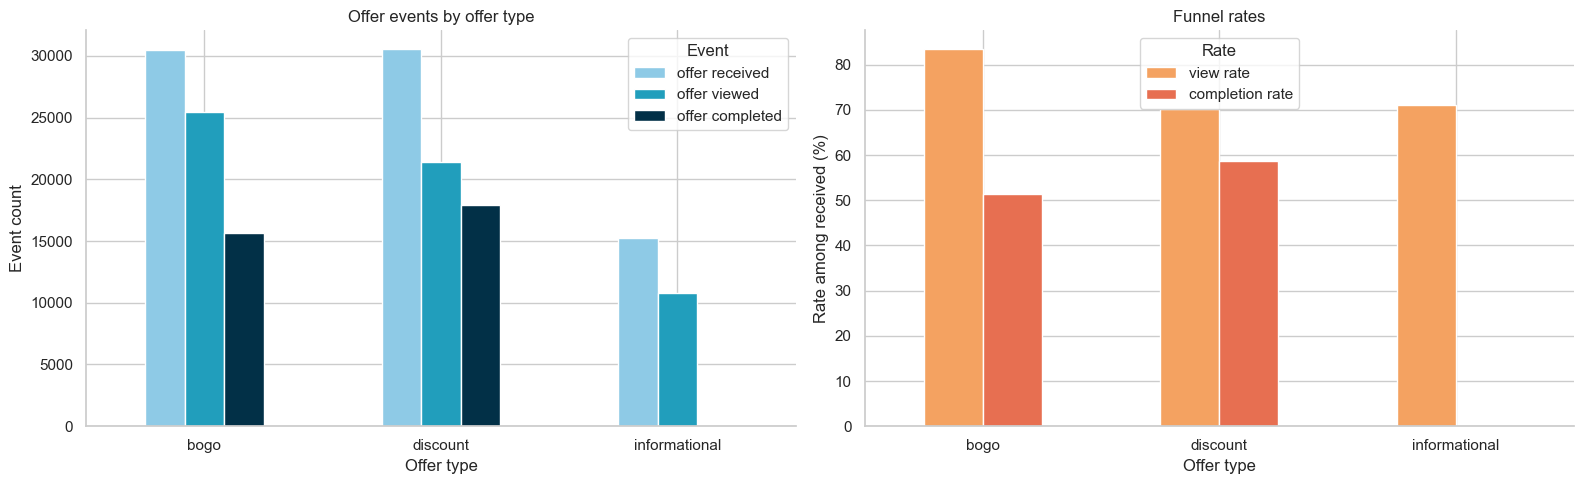

,view rate,completion rate
offer_type,,
bogo,83.44,51.38
discount,70.21,58.64
informational,71.09,0.00


In [5]:
funnel_events = events[events["event"].isin(["offer received", "offer viewed", "offer completed"])].copy()
funnel = funnel_events.groupby(["offer_type", "event"]).size().unstack(fill_value=0)
funnel = funnel.reindex(index=["bogo", "discount", "informational"], columns=["offer received", "offer viewed", "offer completed"], fill_value=0)
rates = pd.DataFrame(index=funnel.index)
rates["view rate"] = funnel["offer viewed"] / funnel["offer received"] * 100
rates["completion rate"] = funnel["offer completed"] / funnel["offer received"] * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
funnel.plot(kind="bar", ax=axes[0], color=["#8ecae6", "#219ebc", "#023047"], rot=0)
axes[0].set(title="Offer events by offer type", xlabel="Offer type", ylabel="Event count")
axes[0].legend(title="Event")
rates.plot(kind="bar", ax=axes[1], color=["#f4a261", "#e76f51"], rot=0)
axes[1].set(title="Funnel rates", xlabel="Offer type", ylabel="Rate among received (%)")
axes[1].legend(title="Rate")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
rates.round(2)

## 4. Offer outcomes across demographic groups

C:\Users\makhi\AppData\Local\Temp\ipykernel_11932\46604098.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  received = demographic_events[demographic_events["event"] == "offer received"].groupby(["age_band", "offer_type"]).size().rename("received")
C:\Users\makhi\AppData\Local\Temp\ipykernel_11932\46604098.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  completed = demographic_events[demographic_events["event"] == "offer completed"].groupby(["age_band", "offer_type"]).size().rename("completed")


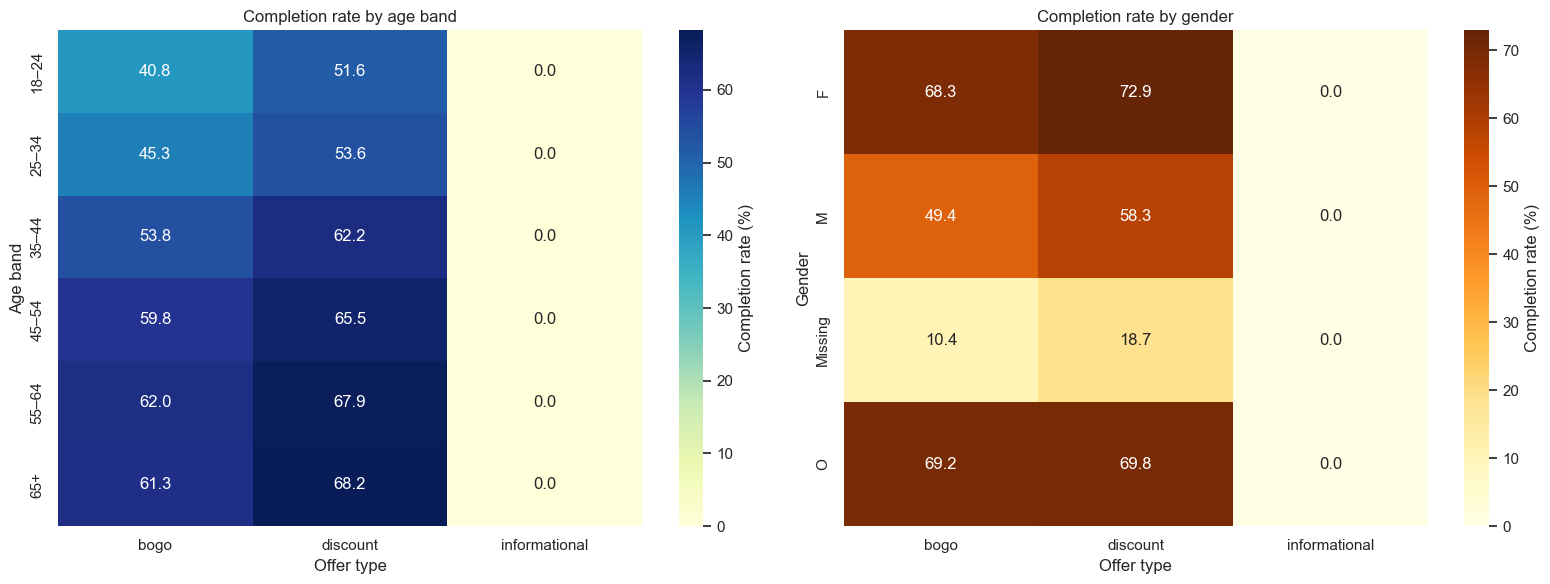

Note: informational offers can have a completion rate of zero because they are not reward-bearing offers.


In [6]:
# Join customer demographics to offer events and compare completion rates.
demographic_events = funnel_events.merge(profile[["id", "gender", "age_band", "income_k"]], left_on="person", right_on="id", how="left")
received = demographic_events[demographic_events["event"] == "offer received"].groupby(["age_band", "offer_type"]).size().rename("received")
completed = demographic_events[demographic_events["event"] == "offer completed"].groupby(["age_band", "offer_type"]).size().rename("completed")
age_outcomes = pd.concat([received, completed], axis=1).fillna(0)
age_outcomes["completion_rate"] = 100 * age_outcomes["completed"] / age_outcomes["received"]
age_heatmap = age_outcomes["completion_rate"].unstack("offer_type").reindex(columns=["bogo", "discount", "informational"])

gender_events = demographic_events.copy()
gender_events["gender"] = gender_events["gender"].fillna("Missing")
gender_received = gender_events[gender_events["event"] == "offer received"].groupby(["gender", "offer_type"]).size().rename("received")
gender_completed = gender_events[gender_events["event"] == "offer completed"].groupby(["gender", "offer_type"]).size().rename("completed")
gender_outcomes = pd.concat([gender_received, gender_completed], axis=1).fillna(0)
gender_outcomes["completion_rate"] = 100 * gender_outcomes["completed"] / gender_outcomes["received"]
gender_heatmap = gender_outcomes["completion_rate"].unstack("offer_type").reindex(columns=["bogo", "discount", "informational"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(age_heatmap, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Completion rate (%)"}, ax=axes[0])
axes[0].set(title="Completion rate by age band", xlabel="Offer type", ylabel="Age band")
sns.heatmap(gender_heatmap, annot=True, fmt=".1f", cmap="YlOrBr", cbar_kws={"label": "Completion rate (%)"}, ax=axes[1])
axes[1].set(title="Completion rate by gender", xlabel="Offer type", ylabel="Gender")
plt.tight_layout()
plt.show()

print("Note: informational offers can have a completion rate of zero because they are not reward-bearing offers.")

## Key takeaways to discuss

- The demographic charts make missingness visible; age 118 is excluded as a sentinel and missing gender/income are retained as an explicit category where appropriate.
- The offer portfolio charts separate offer design from observed response, so a small number of offer definitions is not confused with the much larger number of customer events.
- Funnel rates are descriptive event ratios. They should be interpreted alongside exposure volume and the project’s future leakage-free treatment/outcome table.